# Detecção de Fraudes em Transações de Cartão de Crédito

Este notebook desenvolve um pipeline completo de classificação para identificar fraudes em uma base extremamente desbalanceada.

## Objetivos
- Carregar os dados diretamente da fonte, sem versionar o CSV.
- Explorar o desbalanceamento da variável-alvo `Class`.
- Preparar os dados sem vazamento de informação.
- Comparar Regressão Logística, Random Forest e XGBoost.
- Avaliar precisão, recall, F1, ROC AUC e PR AUC para a classe de fraude.
- Ajustar o limiar de decisão para aumentar a captura de fraudes.
- Testar hiperparâmetros com `GridSearchCV`, usando recall como métrica de seleção.
- Explicar as decisões do melhor modelo com importância das variáveis e SHAP.

> **Importante:** em um problema no qual fraudes são raras, acurácia elevada não garante um modelo útil. O foco principal será a classe `1`.

## 1. Instalação e importação das bibliotecas

In [ ]:
# Execute esta célula no Google Colab.
%pip install -q xgboost shap imbalanced-learn

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

## 2. Carregamento dos dados

In [ ]:
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(DATA_URL)
print(f"Dimensões: {df.shape[0]:,} linhas e {df.shape[1]} colunas")
df.head()

Dimensões: 284,807 linhas e 31 colunas


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
print("Valores ausentes:", int(df.isna().sum().sum()))
print("Duplicidades:", int(df.duplicated().sum()))
df.describe().T

Valores ausentes: 0
Duplicidades: 1081


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


## 3. Análise exploratória

A variável `Class` é a resposta do problema:
- `0`: transação normal;
- `1`: fraude.

As variáveis `V1` a `V28` foram transformadas por PCA. `Time` representa o momento da transação e `Amount`, seu valor.

In [ ]:
contagem = df["Class"].value_counts().sort_index()
proporcao = df["Class"].value_counts(normalize=True).sort_index().mul(100)
resumo_classes = pd.DataFrame({"quantidade": contagem, "percentual": proporcao})
resumo_classes.index = ["Normal (0)", "Fraude (1)"]
resumo_classes

,quantidade,percentual
Normal (0),284315,99.827251
Fraude (1),492,0.172749


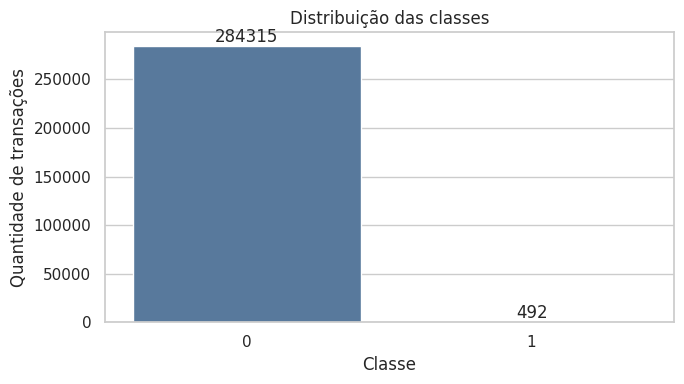

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="Class", ax=ax, palette=["#4C78A8", "#E45756"])
ax.set_title("Distribuição das classes")
ax.set_xlabel("Classe")
ax.set_ylabel("Quantidade de transações")
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
plt.tight_layout()
plt.show()

### Por que a acurácia engana?

Se aproximadamente 99,8% das transações forem normais, um classificador que sempre responda “normal” alcançará cerca de 99,8% de acurácia, embora não detecte nenhuma fraude. Por isso, analisaremos principalmente:

- **Recall da fraude:** proporção das fraudes reais encontradas.
- **Precisão da fraude:** proporção dos alertas de fraude que estavam corretos.
- **F1 da fraude:** equilíbrio entre precisão e recall.
- **PR AUC:** resume a relação entre precisão e recall em diferentes limiares e é especialmente informativa em dados desbalanceados.

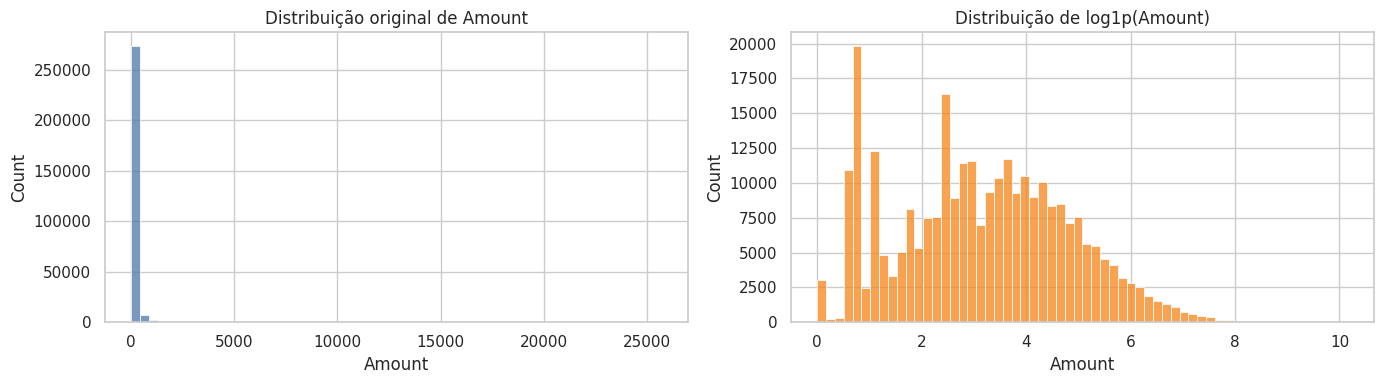

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Amount"], bins=60, ax=axes[0], color="#4C78A8")
axes[0].set_title("Distribuição original de Amount")
sns.histplot(np.log1p(df["Amount"]), bins=60, ax=axes[1], color="#F58518")
axes[1].set_title("Distribuição de log1p(Amount)")
plt.tight_layout()
plt.show()

## 4. Preparação dos dados

In [ ]:
dados = df.copy()
dados["Log_Amount"] = np.log1p(dados["Amount"])
dados = dados.drop(columns=["Amount"])

X = dados.drop(columns=["Class"])
y = dados["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Treino:", X_train.shape, "| Fraudes:", int(y_train.sum()))
print("Teste: ", X_test.shape, "| Fraudes:", int(y_test.sum()))
print("Proporção de fraude no treino:", f"{y_train.mean():.4%}")
print("Proporção de fraude no teste: ", f"{y_test.mean():.4%}")

Treino: (227845, 30) | Fraudes: 394
Teste:  (56962, 30) | Fraudes: 98
Proporção de fraude no treino: 0.1729%
Proporção de fraude no teste:  0.1720%


O `stratify=y` preserva aproximadamente a mesma proporção de fraudes nos conjuntos de treino e teste. A padronização será feita dentro de um `Pipeline`, evitando que informações do teste sejam usadas no ajuste do `StandardScaler`.

## 5. Funções de avaliação

In [ ]:
def avaliar_modelo(nome, y_true, probabilidades, limiar=0.5, mostrar=True):
    predicoes = (probabilidades >= limiar).astype(int)
    metricas = {
        "modelo": nome,
        "limiar": limiar,
        "precisao_fraude": precision_score(y_true, predicoes, zero_division=0),
        "recall_fraude": recall_score(y_true, predicoes, zero_division=0),
        "f1_fraude": f1_score(y_true, predicoes, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilidades),
        "pr_auc": average_precision_score(y_true, probabilidades)
    }
    if mostrar:
        print(classification_report(y_true, predicoes, digits=4))
        matriz = confusion_matrix(y_true, predicoes)
        fig, ax = plt.subplots(figsize=(5, 4))
        sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", ax=ax)
        ax.set_title(f"Matriz de confusão - {nome} (limiar={limiar})")
        ax.set_xlabel("Predição")
        ax.set_ylabel("Real")
        plt.tight_layout()
        plt.show()
    return metricas


def plotar_curvas(nome, y_true, probabilidades):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    RocCurveDisplay.from_predictions(y_true, probabilidades, ax=axes[0], name=nome)
    axes[0].set_title(f"Curva ROC - {nome}")
    PrecisionRecallDisplay.from_predictions(y_true, probabilidades, ax=axes[1], name=nome)
    axes[1].set_title(f"Curva Precisão-Recall - {nome}")
    plt.tight_layout()
    plt.show()

## 6. Modelos

### 6.1 Regressão Logística: baseline

              precision    recall  f1-score   support

           0     0.9999    0.9753    0.9874     56864
           1     0.0603    0.9184    0.1131        98

    accuracy                         0.9752     56962
   macro avg     0.5301    0.9468    0.5503     56962
weighted avg     0.9982    0.9752    0.9859     56962



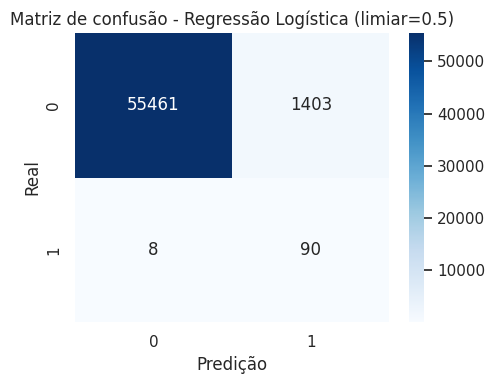

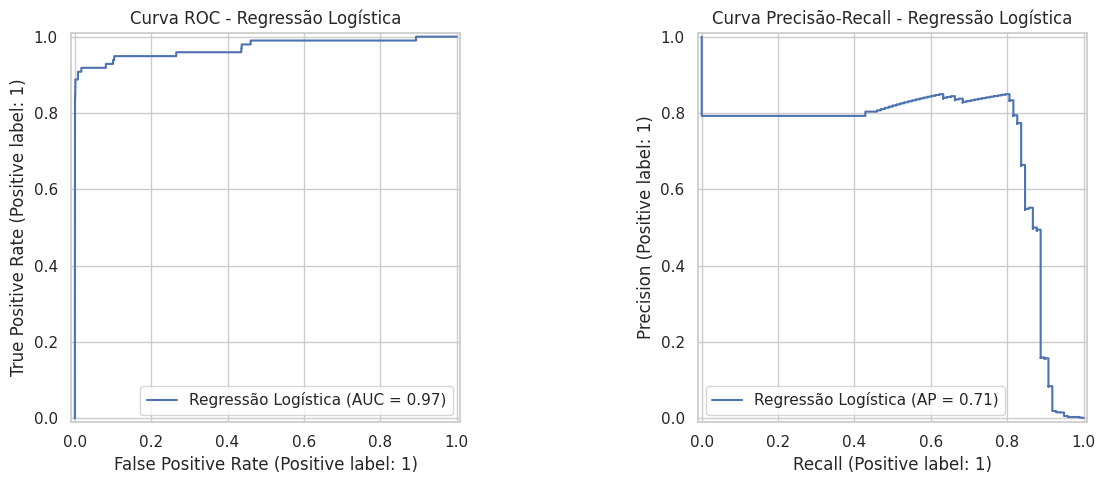

In [ ]:
modelo_logistico = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

modelo_logistico.fit(X_train, y_train)
prob_logistica = modelo_logistico.predict_proba(X_test)[:, 1]
metricas_logistica = avaliar_modelo("Regressão Logística", y_test, prob_logistica)
plotar_curvas("Regressão Logística", y_test, prob_logistica)

### 6.2 Random Forest

              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56864
           1     0.9610    0.7551    0.8457        98

    accuracy                         0.9995     56962
   macro avg     0.9803    0.8775    0.9227     56962
weighted avg     0.9995    0.9995    0.9995     56962



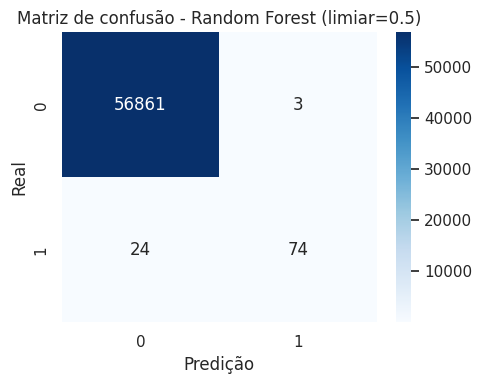

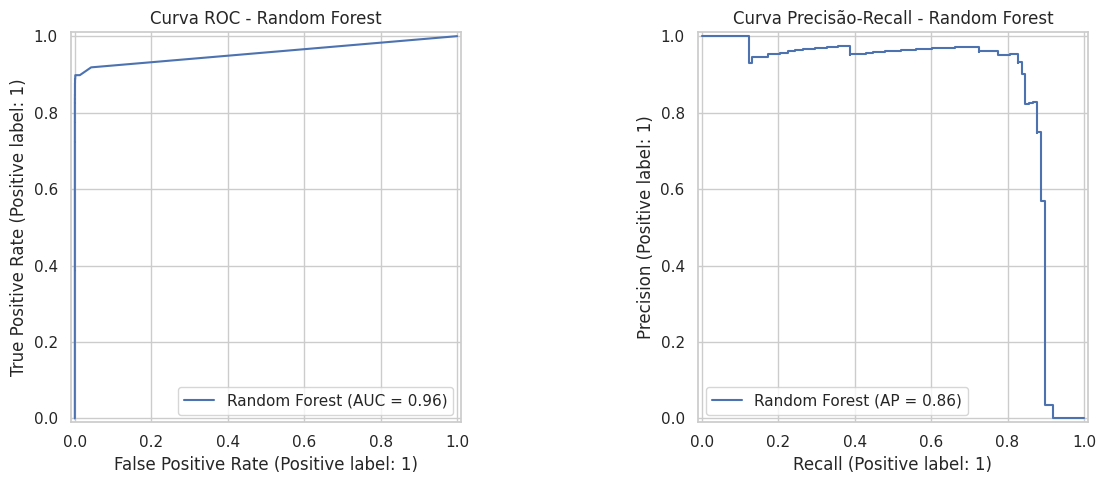

In [ ]:
modelo_rf = RandomForestClassifier(
    n_estimators=250,
    max_depth=None,
    min_samples_leaf=1,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE
)
modelo_rf.fit(X_train, y_train)
prob_rf = modelo_rf.predict_proba(X_test)[:, 1]
metricas_rf = avaliar_modelo("Random Forest", y_test, prob_rf)
plotar_curvas("Random Forest", y_test, prob_rf)

### 6.3 XGBoost

              precision    recall  f1-score   support

           0     0.9998    0.9988    0.9993     56864
           1     0.5548    0.8776    0.6798        98

    accuracy                         0.9986     56962
   macro avg     0.7773    0.9382    0.8396     56962
weighted avg     0.9990    0.9986    0.9987     56962



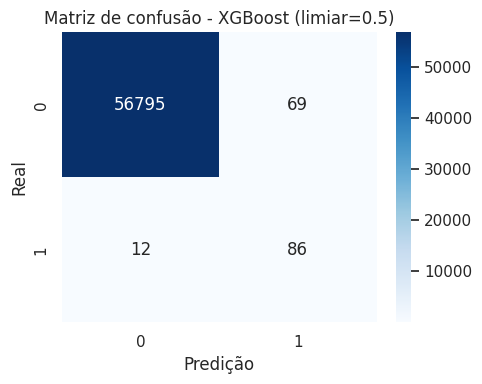

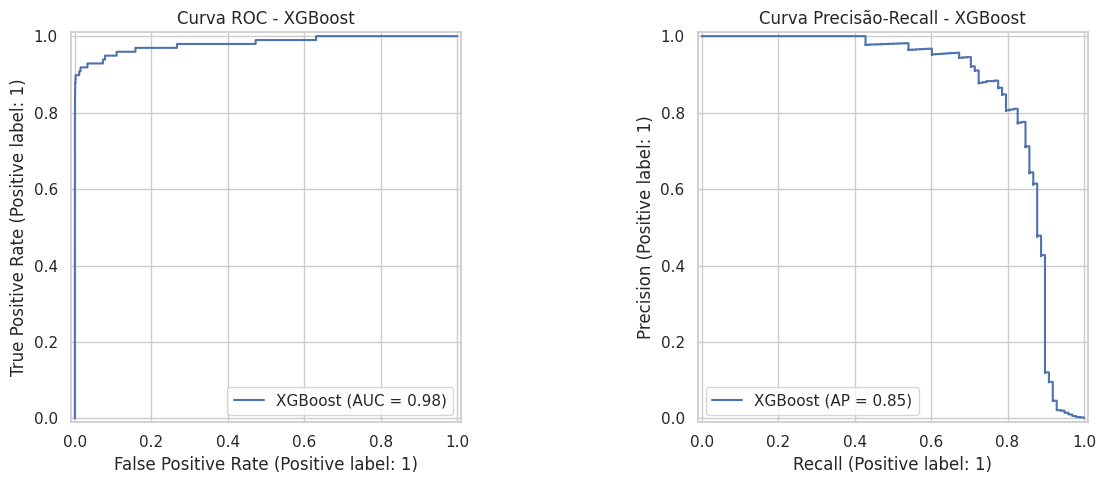

In [ ]:
negativos = int((y_train == 0).sum())
positivos = int((y_train == 1).sum())
scale_pos_weight = negativos / positivos

modelo_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=RANDOM_STATE
)
modelo_xgb.fit(X_train, y_train)
prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]
metricas_xgb = avaliar_modelo("XGBoost", y_test, prob_xgb)
plotar_curvas("XGBoost", y_test, prob_xgb)

## 7. Comparação inicial dos modelos

In [ ]:
comparacao = pd.DataFrame([
    metricas_logistica,
    metricas_rf,
    metricas_xgb
]).sort_values(["recall_fraude", "f1_fraude"], ascending=False)
comparacao.style.format({
    "limiar": "{:.2f}",
    "precisao_fraude": "{:.4f}",
    "recall_fraude": "{:.4f}",
    "f1_fraude": "{:.4f}",
    "roc_auc": "{:.4f}",
    "pr_auc": "{:.4f}"
})

,modelo,limiar,precisao_fraude,recall_fraude,f1_fraude,roc_auc,pr_auc
0,Regressão Logística,0.50,0.0603,0.9184,0.1131,0.9711,0.7113
2,XGBoost,0.50,0.5548,0.8776,0.6798,0.9810,0.8492
1,Random Forest,0.50,0.9610,0.7551,0.8457,0.9568,0.8577


### Como escolher

Como o custo de deixar uma fraude passar costuma ser alto, o recall da classe `1` recebe prioridade. Entretanto, uma precisão excessivamente baixa gera muitos falsos positivos e aumenta o esforço de análise. Por isso, a escolha final deve considerar recall, precisão, F1, PR AUC e a capacidade operacional de revisar alertas.

## 8. Ajuste do limiar de decisão

In [ ]:
# A regressão logística será usada para demonstrar o efeito da mudança de limiar.
limiares = np.arange(0.05, 0.96, 0.05)
linhas = []
for limiar in limiares:
    pred = (prob_logistica >= limiar).astype(int)
    linhas.append({
        "limiar": limiar,
        "precisao": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "alertas": int(pred.sum())
    })
metricas_limites = pd.DataFrame(linhas)
metricas_limites

,limiar,precisao,recall,f1,alertas
0,0.05,0.004963,0.959184,0.009874,18942
1,0.10,0.007986,0.948980,0.015838,11646
2,0.15,0.011628,0.948980,0.022974,7998
3,0.20,0.015735,0.938776,0.030950,5847
4,0.25,0.020362,0.918367,0.039841,4420
5,0.30,0.026224,0.918367,0.050992,3432
6,0.35,0.033137,0.918367,0.063966,2716
7,0.40,0.041096,0.918367,0.078671,2190
8,0.45,0.050167,0.918367,0.095137,1794
9,0.50,0.060281,0.918367,0.113136,1493


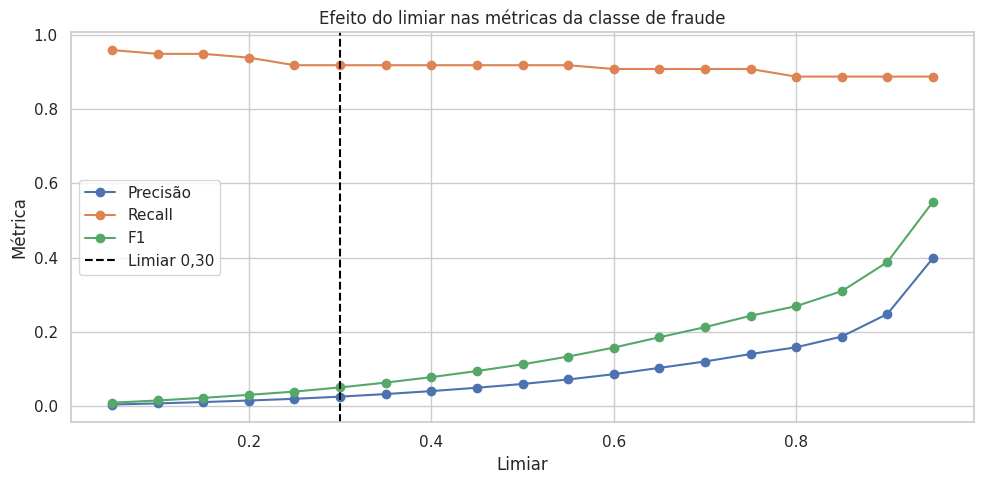

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(metricas_limites["limiar"], metricas_limites["precisao"], marker="o", label="Precisão")
ax.plot(metricas_limites["limiar"], metricas_limites["recall"], marker="o", label="Recall")
ax.plot(metricas_limites["limiar"], metricas_limites["f1"], marker="o", label="F1")
ax.axvline(0.30, linestyle="--", color="black", label="Limiar 0,30")
ax.set_title("Efeito do limiar nas métricas da classe de fraude")
ax.set_xlabel("Limiar")
ax.set_ylabel("Métrica")
ax.legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0     0.9999    0.9412    0.9697     56864
           1     0.0262    0.9184    0.0510        98

    accuracy                         0.9412     56962
   macro avg     0.5130    0.9298    0.5103     56962
weighted avg     0.9982    0.9412    0.9681     56962



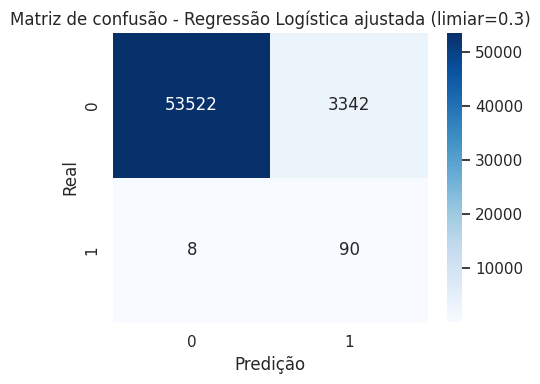

In [ ]:
metricas_logistica_03 = avaliar_modelo(
    "Regressão Logística ajustada",
    y_test,
    prob_logistica,
    limiar=0.30
)

Baixar o limiar de `0,50` para `0,30` normalmente aumenta o recall, pois o modelo aceita uma probabilidade menor para gerar um alerta. A contrapartida esperada é a redução da precisão e o aumento de falsos positivos. A decisão deve ser justificada pelo custo relativo desses dois erros.

## 9. GridSearchCV com seleção por recall

Melhores parâmetros: {'modelo__C': 1.0, 'modelo__solver': 'liblinear'}
Melhor recall médio na validação: 0.9163
              precision    recall  f1-score   support

           0     0.9999    0.9753    0.9874     56864
           1     0.0602    0.9184    0.1131        98

    accuracy                         0.9752     56962
   macro avg     0.5300    0.9468    0.5502     56962
weighted avg     0.9982    0.9752    0.9859     56962



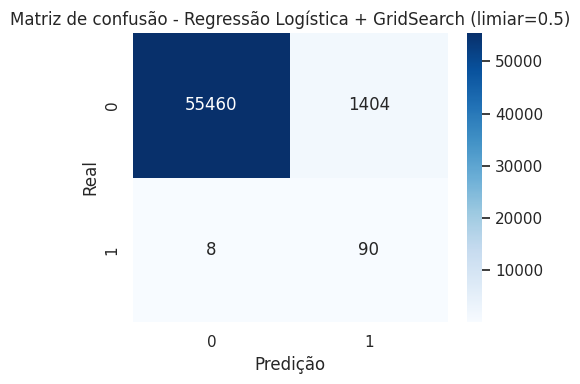

In [ ]:
# Para reduzir o tempo no Colab, a grade é propositalmente compacta.
pipeline_grid = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    "modelo__C": [0.01, 0.1, 1.0, 10.0],
    "modelo__solver": ["liblinear", "lbfgs"]
}

grid = GridSearchCV(
    estimator=pipeline_grid,
    param_grid=param_grid,
    scoring="recall",
    cv=3,
    n_jobs=-1,
    return_train_score=True
)

grid.fit(X_train, y_train)
print("Melhores parâmetros:", grid.best_params_)
print("Melhor recall médio na validação:", round(grid.best_score_, 4))

melhor_logistica = grid.best_estimator_
prob_grid = melhor_logistica.predict_proba(X_test)[:, 1]
metricas_grid = avaliar_modelo("Regressão Logística + GridSearch", y_test, prob_grid)

## 10. Comparação com oversampling e undersampling

In [ ]:
# A reamostragem é aplicada somente ao conjunto de treino.
over = RandomOverSampler(random_state=RANDOM_STATE)
under = RandomUnderSampler(random_state=RANDOM_STATE)

X_over, y_over = over.fit_resample(X_train, y_train)
X_under, y_under = under.fit_resample(X_train, y_train)

modelo_over = clone(modelo_logistico)
modelo_under = clone(modelo_logistico)
modelo_over.fit(X_over, y_over)
modelo_under.fit(X_under, y_under)

prob_over = modelo_over.predict_proba(X_test)[:, 1]
prob_under = modelo_under.predict_proba(X_test)[:, 1]

metricas_over = avaliar_modelo("Regressão Logística + Oversampling", y_test, prob_over, mostrar=False)
metricas_under = avaliar_modelo("Regressão Logística + Undersampling", y_test, prob_under, mostrar=False)

pd.DataFrame([metricas_logistica, metricas_over, metricas_under]).sort_values(
    ["recall_fraude", "f1_fraude"], ascending=False
)

,modelo,limiar,precisao_fraude,recall_fraude,f1_fraude,roc_auc,pr_auc
0,Regressão Logística,0.5,0.060281,0.918367,0.113136,0.971117,0.711314
1,Regressão Logística + Oversampling,0.5,0.060281,0.918367,0.113136,0.970934,0.711364
2,Regressão Logística + Undersampling,0.5,0.052265,0.918367,0.098901,0.974456,0.455597


## 11. Importância das variáveis

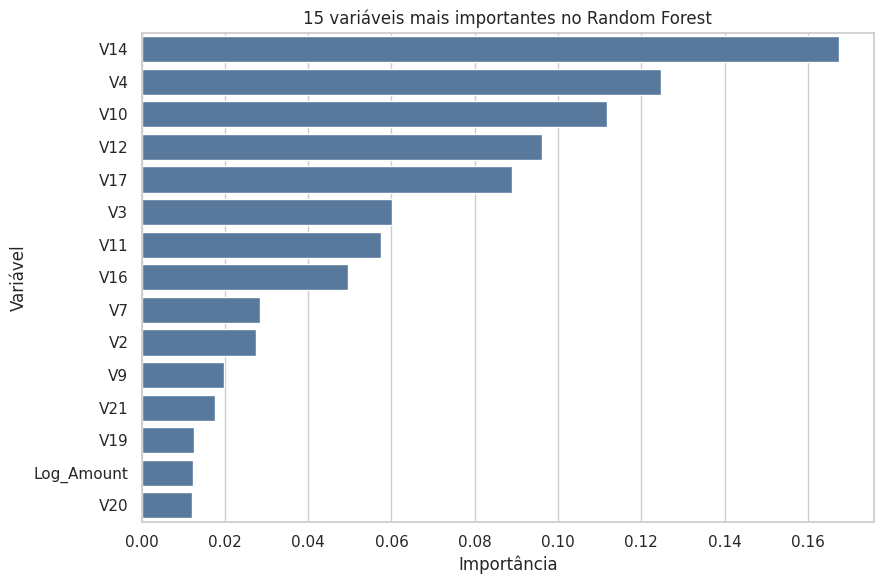

In [ ]:
importancias_rf = pd.Series(modelo_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=importancias_rf.values, y=importancias_rf.index, ax=ax, color="#4C78A8")
ax.set_title("15 variáveis mais importantes no Random Forest")
ax.set_xlabel("Importância")
ax.set_ylabel("Variável")
plt.tight_layout()
plt.show()

## 12. Explicabilidade com SHAP

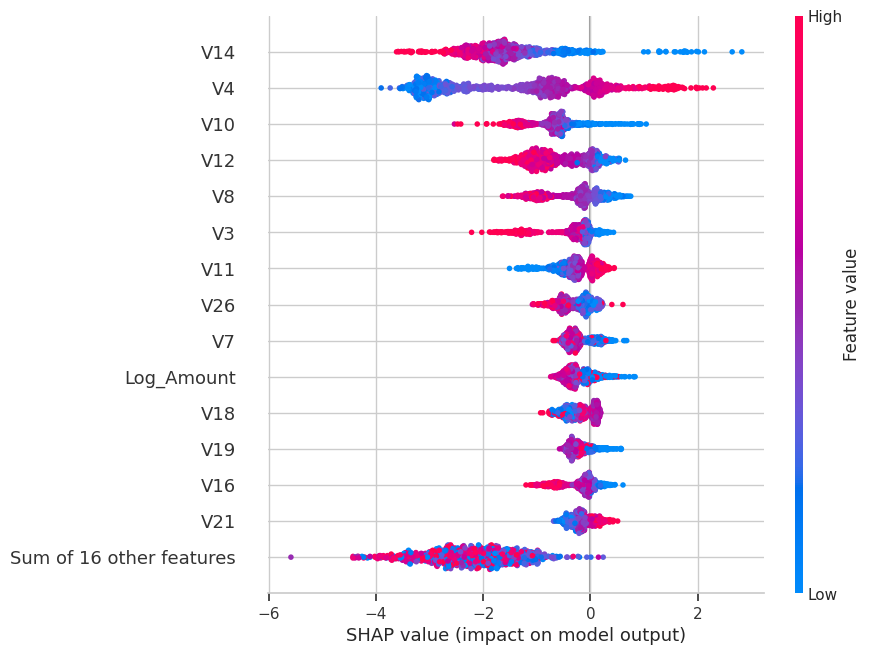

In [ ]:
# Usamos uma amostra para manter a execução viável no Colab.
amostra_shap = X_test.sample(n=min(1000, len(X_test)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(amostra_shap)

shap.plots.beeswarm(shap_values, max_display=15)

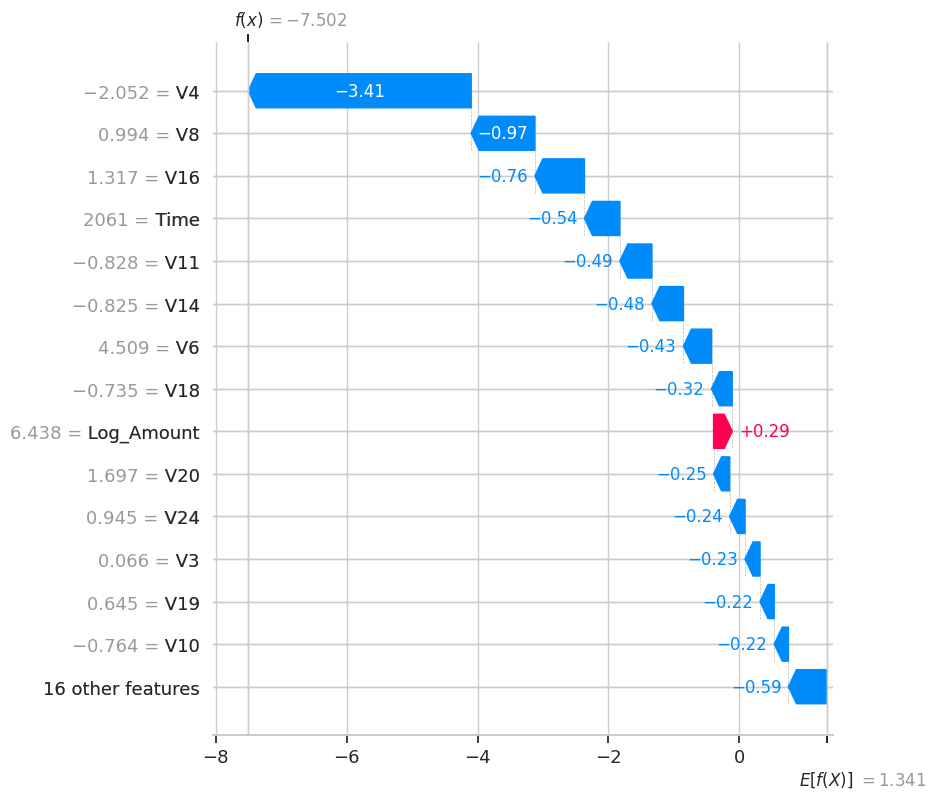

In [ ]:
# Explicação local da primeira transação da amostra.
shap.plots.waterfall(shap_values[0], max_display=15)

### Como interpretar o SHAP

No gráfico global, as variáveis no topo são as que mais influenciaram as previsões. Cada ponto representa uma transação. Valores SHAP positivos empurram a previsão em direção à fraude; valores negativos reduzem essa probabilidade.

O gráfico local `waterfall` explica uma transação específica. Ele mostra quais variáveis aumentaram ou reduziram a saída do modelo. Como `V1` a `V28` foram anonimizadas por PCA, é possível explicar a influência estatística, mas não atribuir um significado de negócio direto a cada componente.

## 13. Resumo final automático

In [ ]:
resultado_final = pd.DataFrame([
    metricas_logistica,
    metricas_logistica_03,
    metricas_rf,
    metricas_xgb,
    metricas_grid,
    metricas_over,
    metricas_under
]).sort_values(["recall_fraude", "f1_fraude"], ascending=False)

resultado_final.to_csv("comparacao_modelos.csv", index=False)
resultado_final.style.format({
    "limiar": "{:.2f}",
    "precisao_fraude": "{:.4f}",
    "recall_fraude": "{:.4f}",
    "f1_fraude": "{:.4f}",
    "roc_auc": "{:.4f}",
    "pr_auc": "{:.4f}"
})

,modelo,limiar,precisao_fraude,recall_fraude,f1_fraude,roc_auc,pr_auc
0,Regressão Logística,0.50,0.0603,0.9184,0.1131,0.9711,0.7113
5,Regressão Logística + Oversampling,0.50,0.0603,0.9184,0.1131,0.9709,0.7114
4,Regressão Logística + GridSearch,0.50,0.0602,0.9184,0.1131,0.9712,0.7113
6,Regressão Logística + Undersampling,0.50,0.0523,0.9184,0.0989,0.9745,0.4556
1,Regressão Logística ajustada,0.30,0.0262,0.9184,0.0510,0.9711,0.7113
3,XGBoost,0.50,0.5548,0.8776,0.6798,0.9810,0.8492
2,Random Forest,0.50,0.9610,0.7551,0.8457,0.9568,0.8577


In [ ]:
melhor = resultado_final.iloc[0]
print("Modelo com maior recall no teste:", melhor["modelo"])
print(f"Limiar: {melhor['limiar']:.2f}")
print(f"Precisão da fraude: {melhor['precisao_fraude']:.4f}")
print(f"Recall da fraude: {melhor['recall_fraude']:.4f}")
print(f"F1 da fraude: {melhor['f1_fraude']:.4f}")
print(f"PR AUC: {melhor['pr_auc']:.4f}")

Modelo com maior recall no teste: Regressão Logística
Limiar: 0.50
Precisão da fraude: 0.0603
Recall da fraude: 0.9184
F1 da fraude: 0.1131
PR AUC: 0.7113


## 14. Conclusões

Este projeto demonstrou que a acurácia isolada é inadequada para avaliar detecção de fraude. A seleção do modelo foi orientada principalmente pelo recall da classe `1`, complementado por precisão, F1 e PR AUC.

A redução do limiar aumentou a sensibilidade do modelo, mas também elevou a quantidade de falsos positivos. Essa troca deve ser ajustada de acordo com o custo de uma fraude não detectada e com a capacidade operacional de investigar alertas.

O SHAP permitiu identificar quais componentes mais influenciaram as previsões globais e explicar transações individuais. Entretanto, como `V1` a `V28` são componentes anonimizados por PCA, sua interpretação de negócio é limitada.

### Evoluções futuras
- Validar o limiar com uma função explícita de custo financeiro.
- Usar validação cruzada estratificada com mais divisões.
- Avaliar estabilidade temporal e possível mudança de comportamento.
- Criar variáveis de frequência e sequência de transações.
- Testar técnicas como SMOTE e modelos adicionais.
- Monitorar recall, precisão, taxa de alertas e drift em produção.